In [5]:
import pandas as pd
import os

%matplotlib

os.chdir(r'C:\Users\USER\Documents\GitHub\wine_type_classifier')

w_wine_df = pd.read_csv('winequality-white.csv', sep=';')
r_wine_df = pd.read_csv('winequality-red.csv', sep=';')


w_wine_df['type'] = 'white'
r_wine_df['type'] = 'red'

print(w_wine_df.shape, r_wine_df.shape)

wine_df = pd.concat([w_wine_df, r_wine_df])
wine_df.head()

Using matplotlib backend: module://matplotlib_inline.backend_inline
(4898, 13) (1599, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white


In [6]:
print(wine_df.shape)
wine_df.describe()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


array([[<Axes: title={'center': 'fixed acidity'}>,
        <Axes: title={'center': 'free sulfur dioxide'}>],
       [<Axes: title={'center': 'total sulfur dioxide'}>, <Axes: >]],
      dtype=object)

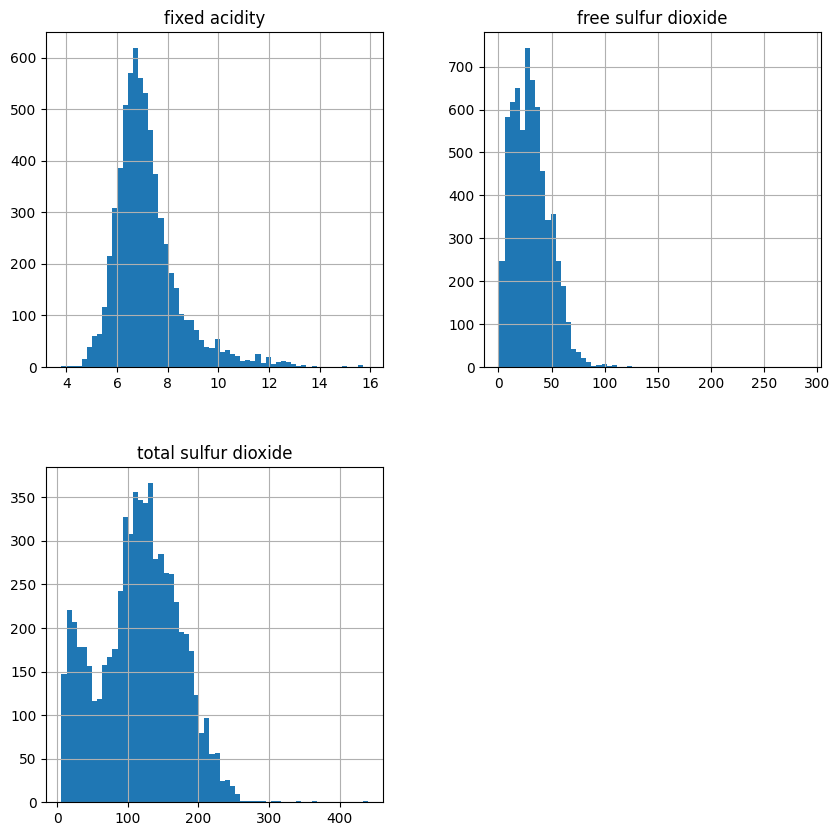

In [7]:
wine_df[['fixed acidity', 'free sulfur dioxide', 'total sulfur dioxide', ]].hist(bins=60, figsize=(10,10))

In [8]:
wine_df[wine_df['citric acid'] > 0.8]['chlorides'].count()

np.int64(17)

In [9]:
wine_df_cleaned = wine_df[(wine_df['free sulfur dioxide'] < 100) & (wine_df['total sulfur dioxide'] < 250)
                          & (wine_df['fixed acidity'] < 14) & (wine_df['density'] < 1) & (wine_df['chlorides'] < 0.1)
                          & (wine_df['pH'] < 3.7) & (wine_df['sulphates'] < 1.2) & (wine_df['citric acid'] < 0.8)
                          & (wine_df['volatile acidity'] < 1)]

print(f'Percentage of Data after cleaning: {round(100*(wine_df_cleaned.shape[0] / wine_df.shape[0]),2)}')


Percentage of Data after cleaning: 90.78


array([[<Axes: title={'center': 'fixed acidity'}>,
        <Axes: title={'center': 'volatile acidity'}>,
        <Axes: title={'center': 'citric acid'}>],
       [<Axes: title={'center': 'residual sugar'}>,
        <Axes: title={'center': 'chlorides'}>,
        <Axes: title={'center': 'free sulfur dioxide'}>],
       [<Axes: title={'center': 'total sulfur dioxide'}>,
        <Axes: title={'center': 'density'}>,
        <Axes: title={'center': 'pH'}>],
       [<Axes: title={'center': 'sulphates'}>,
        <Axes: title={'center': 'alcohol'}>,
        <Axes: title={'center': 'quality'}>]], dtype=object)

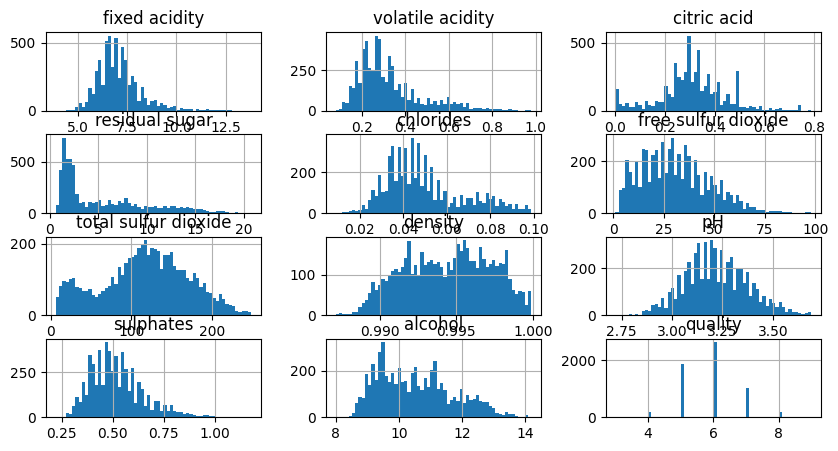

In [10]:
wine_df_cleaned.hist(bins=60, figsize=(10,5))

In [11]:
prep_wine_df = wine_df_cleaned.copy()
prep_wine_df['type'] = prep_wine_df['type'].apply(lambda x: 1 if x == 'red' else 0) #if red set to 1, if white set to 0 

In [12]:
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(prep_wine_df, test_size=0.2, random_state=42)

In [13]:
train_y_set = train_set['type']
train_x_set = train_set.drop(columns='type')

test_y_set = test_set['type']
test_x_set = test_set.drop(columns='type')

In [14]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(train_x_set, train_y_set)



,"loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [15]:
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, train_x_set, train_y_set, cv=3)

In [18]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

print(f'Precision Score: {precision_score(train_y_set, y_train_pred)}, Recall Score: {recall_score(train_y_set, y_train_pred)}, \n Confusion Matrix: {confusion_matrix(train_y_set, y_train_pred)}')

Precision Score: 0.9503464203233256, Recall Score: 0.8124383020730503, 
 Confusion Matrix: [[3662   43]
 [ 190  823]]


In [19]:
y_scores = cross_val_predict(sgd_clf, train_x_set, train_y_set, cv = 3, method='decision_function')

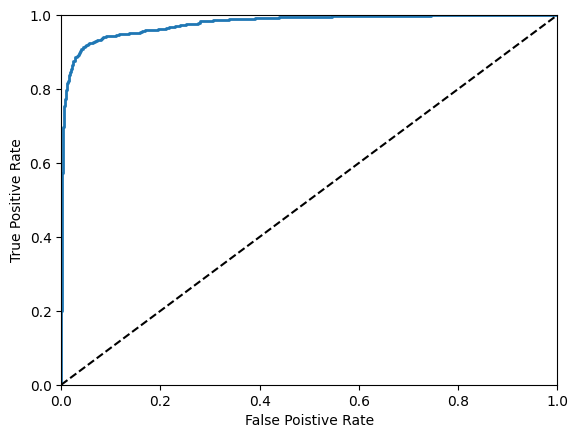

In [24]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, threshold = roc_curve(train_y_set, y_scores)

def plot_roc_curve(fpr, tpr, lable=None):
    plt.plot(fpr, tpr, linewidth=2, label='label')
    plt.plot([0,1],[0,1],'k--')
    plt.axis([0,1,0,1])
    plt.xlabel('False Poistive Rate')
    plt.ylabel('True Positive Rate')

plot_roc_curve(fpr, tpr)


In [25]:
from sklearn.metrics import roc_auc_score

roc_auc_score(train_y_set, y_scores)

0.9780803668370561

In [26]:
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(random_state=42)
y_probas_forest = cross_val_predict(forest_clf, train_x_set, train_y_set, cv=3, method='predict_proba')

In [ ]:
y_scores_forest = y_probas_forest[:,1]
fpr_forest, tpr_forest, threshold_forest = roc_curve(train_y_set, y_scores_forest)

roc_auc_score(train_y_set, y_scores_forest)

0.9983212835033898

In [ ]:
y_train_pred_forest = cross_val_predict(forest_clf, train_x_set, train_y_set, cv=3)

print(f'{precision_score(train_y_set, y_train_pred_forest)}, {recall_score(train_y_set, y_train_pred_forest)}')

0.9920556107249255, 0.9861796643632774
